# COMET vs. CellOracle on Paul et al. 2015 data

Compares COMET's inferred GRNs (`paul2015_outputs_test/`) against a genuine CellOracle GRN for the same dataset, computed in `celloracle_reference.ipynb`.

## Note

CellOracle's GRN is not a single dense matrix — it's a directed, signed graph *per cluster* (`source` TF → `target` gene, `coef_mean`), sparse only after `filter_links` (p-value + top-N-by-|coef| per cluster). A structural zero can mean "regression shrank this to zero" or "this TF-gene pair was never a base-GRN candidate" (no ATAC-linked motif) — different things, and a dense-matrix Spearman across all gene×TF pairs conflates them. Every comparison below either restricts to a rank-based top-set (Jaccard) or a matched-support correlation, rather than correlating full dense matrices.

## A caveat that remains

COMET and CellOracle each derive their own TF-motif/ATAC-based candidate-edge prior independently. The `A_genes`/`A_tfs` *identity* overlap is very high (checked below), but the *candidate edge* set is not guaranteed identical between the two methods.

Kernel: `decipher-env` (no `celloracle` import needed — everything CellOracle-specific was flattened to CSV/npy in the reference notebook).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.stats import spearmanr

COMET_BASE = "/home/elicanter/paul2015_outputs_test"
CO_REF = "/home/elicanter/datasets/paul2015data/celloracle_reference"

EPS = 1e-6

# ---- COMET outputs ----
weights = np.load(f"{COMET_BASE}/mix_weights.npy")                       # (n_cells, D)
A_dict = np.load(f"{COMET_BASE}/A_dict.npy")                             # (D, G, T)
A_genes = np.load(f"{COMET_BASE}/A_genes.npy", allow_pickle=True).astype(str)
A_tfs = np.load(f"{COMET_BASE}/A_tfs.npy", allow_pickle=True).astype(str)
comet_cluster_labels = np.load(f"{COMET_BASE}/cluster_labels.npy")       # (n_cells,) init clusters, D=4

n_cells, D = weights.shape
G, T = len(A_genes), len(A_tfs)
print(f"COMET: {n_cells} cells, D={D} dictionary atoms, G={G} genes, T={T} TFs")

# ---- CellOracle reference ----
cell_meta = pd.read_csv(f"{CO_REF}/cell_metadata.csv", index_col=0)      # all 2671 cells, obs order
network_scores = pd.read_csv(f"{CO_REF}/network_scores.csv", index_col=0)
co_genes_all = np.load(f"{CO_REF}/base_grn_genes.npy", allow_pickle=True).astype(str)
co_tfs_all = np.load(f"{CO_REF}/base_grn_tfs.npy", allow_pickle=True).astype(str)

print(f"CellOracle reference: {len(cell_meta)} cells (metadata), base GRN universe "
      f"{len(co_genes_all)} genes x {len(co_tfs_all)} TFs")

assert len(cell_meta) == n_cells, (
    "Cell count mismatch between COMET output and CellOracle cell metadata — "
    "the positional cell-order alignment assumed below does not hold."
)

import os
cluster_names = sorted(
    f.replace(".csv", "") for f in os.listdir(f"{CO_REF}/edges_by_cluster")
)
edges_by_cluster = {
    cl: pd.read_csv(f"{CO_REF}/edges_by_cluster/{cl}.csv") for cl in cluster_names
}
print(f"CellOracle clusters with a fitted+filtered GRN: {cluster_names}")
for cl, df in edges_by_cluster.items():
    print(f"  {cl:10s}  {len(df):5d} edges")

COMET: 2671 cells, D=4 dictionary atoms, G=1848 genes, T=90 TFs
CellOracle reference: 2671 cells (metadata), base GRN universe 1850 genes x 90 TFs
CellOracle clusters with a fitted+filtered GRN: ['10GMP', '12Baso', '13Baso', '14Mo', '15Mo', '16Neu', '17Neu', '1Ery', '2Ery', '3Ery', '4Ery', '5Ery', '6Ery', '7MEP', '8Mk', '9GMP']
  10GMP        2000 edges
  12Baso       2000 edges
  13Baso       2000 edges
  14Mo         2000 edges
  15Mo         2000 edges
  16Neu        2000 edges
  17Neu        2000 edges
  1Ery         2000 edges
  2Ery         2000 edges
  3Ery         2000 edges
  4Ery         2000 edges
  5Ery         2000 edges
  6Ery         2000 edges
  7MEP         2000 edges
  8Mk          2000 edges
  9GMP         2000 edges


## Align gene/TF universes

Restrict both methods to genes and TFs present in both `A_genes`/`A_tfs` (COMET) and the CellOracle base-GRN universe. This is an identity intersection only — it says nothing yet about whether the same (gene, TF) *edges* are candidates in both; that's handled per-comparison below via top-K / union-support restrictions rather than a dense matrix.

In [2]:
common_genes = np.intersect1d(A_genes, co_genes_all)
common_tfs = np.intersect1d(A_tfs, co_tfs_all)
print(f"Shared genes: {len(common_genes)} / {len(A_genes)} COMET genes, {len(co_genes_all)} CO genes")
print(f"Shared TFs:   {len(common_tfs)} / {len(A_tfs)} COMET TFs, {len(co_tfs_all)} CO TFs")

a_gene_idx = pd.Index(A_genes).get_indexer(common_genes)
a_tf_idx = pd.Index(A_tfs).get_indexer(common_tfs)
A_dict = A_dict[:, a_gene_idx][:, :, a_tf_idx]   # (D, G', T')
A_genes, A_tfs = common_genes, common_tfs
G, T = len(A_genes), len(A_tfs)

gene_pos = {g: i for i, g in enumerate(A_genes)}
tf_pos = {t: i for i, t in enumerate(A_tfs)}


def edges_to_matrix(df, value_col="coef_mean"):
    """Long edge table -> dense (G, T) matrix restricted to the shared gene/TF universe."""
    mat = np.zeros((G, T), dtype=np.float32)
    df = df[df["target"].isin(gene_pos) & df["source"].isin(tf_pos)]
    gi = df["target"].map(gene_pos).to_numpy()
    ti = df["source"].map(tf_pos).to_numpy()
    mat[gi, ti] = df[value_col].to_numpy()
    return mat


co_cluster_mats = {cl: edges_to_matrix(df) for cl, df in edges_by_cluster.items()}
print(f"\nBuilt {len(co_cluster_mats)} CellOracle cluster GRN matrices, each {(G, T)}")

# global (cell-count-weighted) pooled CellOracle GRN, for population-level comparisons only
# (CellOracle has no native notion of a single population GRN — this is our approximation)
cluster_sizes = cell_meta["paul15_clusters"].value_counts()
w = np.array([cluster_sizes.get(cl, 0) for cl in co_cluster_mats])
w = w / w.sum()
co_global = np.tensordot(w, np.stack(list(co_cluster_mats.values())), axes=1)   # (G, T)
print("Built cell-count-weighted global CellOracle GRN")

Shared genes: 1848 / 1848 COMET genes, 1850 CO genes
Shared TFs:   89 / 90 COMET TFs, 90 CO TFs

Built 16 CellOracle cluster GRN matrices, each (1848, 89)
Built cell-count-weighted global CellOracle GRN


## Metrics

Two comparison metrics, both operating per-TF (a TF's regulon) and both avoiding the shared-structural-zero problem described above:

- **Per-TF top-K Jaccard** (same metric as `analysis7.ipynb`, kept — it's the one part of the old analysis that was already principled): for each TF, take the top `top_frac` genes by |weight| from each GRN (restricted to that TF's nonzero/candidate genes only), and compute Jaccard overlap of the two top sets.
- **Per-TF union-support Spearman**: restrict to the union of genes either GRN considers a candidate for that TF, then Spearman-correlate the (signed) weights on exactly that support. This is the fix for the old "hub TF" cell, which computed Spearman naively.

In [3]:
TOP_FRAC = 0.10


def avg_per_tf_topk_jaccard(grn1, grn2, top_frac=TOP_FRAC, eps=EPS):
    """Mean over TFs of Jaccard between each GRN's top-`top_frac` strongest genes
    (fraction taken over genes nonzero in EITHER GRN for that TF)."""
    j = []
    for t in range(grn1.shape[1]):
        x, y = np.abs(grn1[:, t]), np.abs(grn2[:, t])
        nz_x, nz_y = np.flatnonzero(x > eps), np.flatnonzero(y > eps)
        if len(nz_x) == 0 or len(nz_y) == 0:
            continue
        n_u = len(np.union1d(nz_x, nz_y))
        k = max(1, round(top_frac * n_u))
        kx, ky = min(k, len(nz_x)), min(k, len(nz_y))
        tx = set(nz_x[np.argsort(x[nz_x])[::-1][:kx]])
        ty = set(nz_y[np.argsort(y[nz_y])[::-1][:ky]])
        u = tx | ty
        if u:
            j.append(len(tx & ty) / len(u))
    return np.mean(j) if j else np.nan


def avg_per_tf_union_spearman(grn1, grn2, eps=EPS, min_support=5):
    """Mean over TFs of Spearman rho between the two GRNs' (signed) weights,
    restricted to genes nonzero in EITHER GRN for that TF (union support)."""
    rhos = []
    for t in range(grn1.shape[1]):
        x, y = grn1[:, t], grn2[:, t]
        support = np.flatnonzero((np.abs(x) > eps) | (np.abs(y) > eps))
        if len(support) < min_support:
            continue
        rho, _ = spearmanr(x[support], y[support])
        if not np.isnan(rho):
            rhos.append(rho)
    return np.mean(rhos) if rhos else np.nan


def null_jaccard(grn1, grn2, top_frac=TOP_FRAC, n=5, seed=0):
    """Random floor: permute grn2's gene axis, destroying gene correspondence
    while preserving its per-TF magnitude distribution."""
    rng = np.random.default_rng(seed)
    vals = [avg_per_tf_topk_jaccard(grn1, grn2[rng.permutation(grn2.shape[0])], top_frac)
            for _ in range(n)]
    return np.nanmean(vals)

## Population-level comparison

COMET's population-average GRN (mixture weights averaged over all cells, projected through `A_dict`) vs. the cell-count-weighted pooled CellOracle GRN built above. Reported alongside a permutation null (gene-axis shuffle) so the raw Jaccard number has a floor to compare against.

In [4]:
comet_global = np.einsum("d,dgt->gt", weights.mean(axis=0), A_dict)   # (G, T)

jacc = avg_per_tf_topk_jaccard(np.abs(comet_global), np.abs(co_global))
jacc_null = null_jaccard(np.abs(comet_global), np.abs(co_global))
rho = avg_per_tf_union_spearman(np.abs(comet_global), np.abs(co_global))
#rho = avg_per_tf_union_spearman(comet_global, co_global) 

print("=== COMET global GRN vs. CellOracle pooled GRN ===")
print(f"Per-TF top-{int(TOP_FRAC*100)}% Jaccard: {jacc:.4f}  (permutation null: {jacc_null:.4f}, "
      f"{jacc / jacc_null:.2f}x)")
print(f"Per-TF union-support Spearman rho:      {rho:.4f}")

=== COMET global GRN vs. CellOracle pooled GRN ===
Per-TF top-10% Jaccard: 0.1783  (permutation null: 0.0256, 6.97x)
Per-TF union-support Spearman rho:      0.2022


## How COMET's coarse clusters relate to CellOracle's fine-grained cell types

`cluster_labels.npy` is COMET's `D=4` internal dictionary-atom initialization (a KMeans-style pre-clustering used only to warm-start training, saved for analysis — not a stable end product). It is far coarser than CellOracle's 17 `paul15_clusters` cell types. Before comparing GRNs cluster-to-cluster, check what these 4 atoms actually correspond to in terms of real cell type, using the shared cell order.

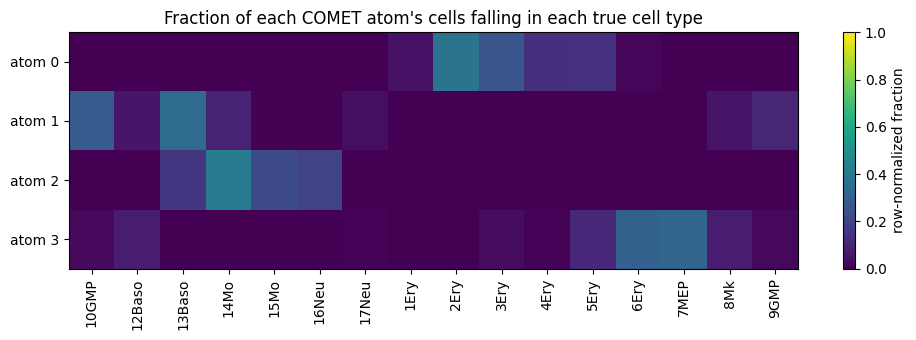

Plurality true cell type per COMET atom:
COMET_atom
0      2Ery
1    13Baso
2      14Mo
3      7MEP
dtype: object


In [5]:
true_labels = cell_meta["paul15_clusters"].to_numpy()  # positional, same cell order as COMET arrays

contingency = pd.crosstab(
    pd.Series(comet_cluster_labels, name="COMET_atom"),
    pd.Series(true_labels, name="CellOracle_paul15_cluster"),
)
contingency = contingency[[c for c in cluster_names if c in contingency.columns]]  # keep only clusters with a fitted GRN

fig, ax = plt.subplots(figsize=(10, 3.5))
row_norm = contingency.div(contingency.sum(axis=1), axis=0)
im = ax.imshow(row_norm.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_yticks(range(len(row_norm.index))); ax.set_yticklabels([f"atom {i}" for i in row_norm.index])
ax.set_xticks(range(len(row_norm.columns))); ax.set_xticklabels(row_norm.columns, rotation=90)
ax.set_title("Fraction of each COMET atom's cells falling in each true cell type")
fig.colorbar(im, ax=ax, label="row-normalized fraction")
plt.tight_layout()
plt.show()

# for each COMET atom, which true cluster is its plurality cell type?
dominant = contingency.idxmax(axis=1)
print("Plurality true cell type per COMET atom:")
print(dominant)

## Cell-level discrimination: does a cell's inferred GRN look like its own true cell type's CellOracle GRN?

For a sample of cells, build each cell's specific GRN (`weights[cell] @ A_dict`), score its per-TF top-K Jaccard against *every* CellOracle cluster's real filtered GRN, z-normalize each cluster's score column (removes cluster-density/size bias), and predict the best-matching cluster. Compare against the cell's real `paul15_clusters` label. This is the most direct test of whether COMET's cell-specific GRNs carry real cell-type-specific signal, now scored against ground-truth cell types instead of an unrelated dataset's clusters.

In [6]:
N_SAMPLE = 300
N_SHUFFLE = 200
SEED = 0

# only cells whose true label has a fitted CellOracle GRN
eligible = np.flatnonzero(np.isin(true_labels, cluster_names))
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(eligible, size=min(N_SAMPLE, len(eligible)), replace=False)
print(f"Scoring {len(sample_idx)} cells against {len(cluster_names)} CellOracle cluster GRNs")


def precompute_orders(grn_abs, eps=EPS):
    orders, mask = [], np.zeros((T, G), dtype=bool)
    for t in range(T):
        x = grn_abs[:, t]
        nz = np.flatnonzero(x > eps)
        orders.append(nz[np.argsort(x[nz])[::-1]])
        mask[t, nz] = True
    return orders, mask


cl_orders, cl_mask = {}, {}
for cl, mat in co_cluster_mats.items():
    cl_orders[cl], cl_mask[cl] = precompute_orders(np.abs(mat))


def mean_jaccard_to_cluster(cell_orders, cl, top_frac=TOP_FRAC):
    j = []
    for t in range(T):
        ox, oy = cell_orders[t], cl_orders[cl][t]
        if ox.size == 0 or oy.size == 0:
            continue
        overlap_nz = cl_mask[cl][t][ox].sum()
        union_nz = ox.size + oy.size - overlap_nz
        k = max(1, round(top_frac * union_nz))
        kx, ky = min(k, ox.size), min(k, oy.size)
        inter = np.intersect1d(ox[:kx], oy[:ky], assume_unique=True).size
        j.append(inter / (kx + ky - inter))
    return np.mean(j) if j else np.nan


assigned, J_rows = [], []
for i in sample_idx:
    cell_grn = np.abs(np.einsum("d,dgt->gt", weights[i], A_dict))
    cell_orders, _ = precompute_orders(cell_grn)
    J_rows.append([mean_jaccard_to_cluster(cell_orders, cl) for cl in cluster_names])
    assigned.append(true_labels[i])

assigned = np.array(assigned)
J = np.array(J_rows)  # (n_sample, n_clusters)

Z = (J - np.nanmean(J, axis=0, keepdims=True)) / np.nanstd(J, axis=0, keepdims=True)
Z_filled = np.where(np.isnan(Z), -np.inf, Z)
predicted = np.array(cluster_names)[Z_filled.argmax(1)]

acc = (predicted == assigned).mean()
shuffle_acc = np.array([(predicted == rng.permutation(assigned)).mean() for _ in range(N_SHUFFLE)])
p_emp = (shuffle_acc >= acc).mean()

print(f"Accuracy (z-normalized nearest cluster): {acc:.3f}")
print(f"Shuffle null:                            {shuffle_acc.mean():.3f} +/- {shuffle_acc.std():.3f}")
print(f"Nominal chance (1/{len(cluster_names)}):              {1/len(cluster_names):.3f}")
print(f"Empirical p vs shuffle:                  "
      f"{'< %.4f' % (1/N_SHUFFLE) if p_emp == 0 else '%.4f' % p_emp}")

Scoring 300 cells against 16 CellOracle cluster GRNs


Accuracy (z-normalized nearest cluster): 0.010
Shuffle null:                            0.023 +/- 0.006
Nominal chance (1/16):              0.062
Empirical p vs shuffle:                  0.9850


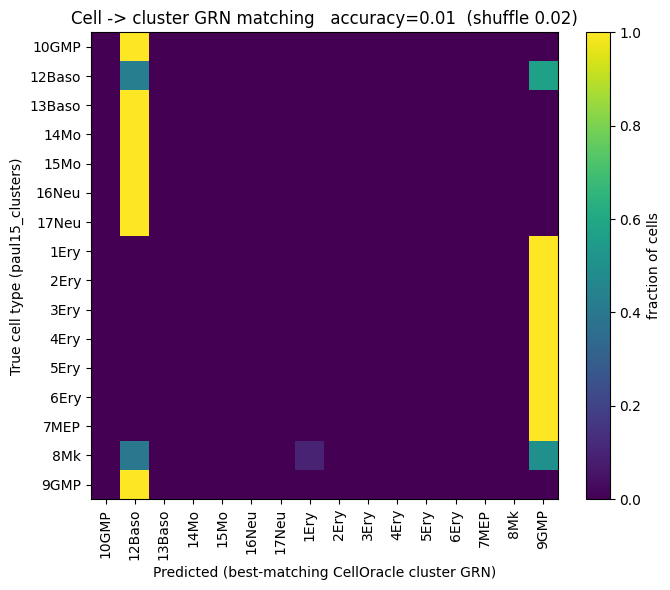

In [7]:
conf = pd.crosstab(pd.Series(assigned, name="true"), pd.Series(predicted, name="predicted"))
conf = conf.reindex(index=cluster_names, columns=cluster_names, fill_value=0)
conf_norm = conf.div(conf.sum(axis=1).replace(0, np.nan), axis=0)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(conf_norm.values, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(cluster_names))); ax.set_xticklabels(cluster_names, rotation=90)
ax.set_yticks(range(len(cluster_names))); ax.set_yticklabels(cluster_names)
ax.set_xlabel("Predicted (best-matching CellOracle cluster GRN)")
ax.set_ylabel("True cell type (paul15_clusters)")
ax.set_title(f"Cell -> cluster GRN matching   accuracy={acc:.2f}  (shuffle {shuffle_acc.mean():.2f})")
fig.colorbar(im, ax=ax, label="fraction of cells", fraction=0.046)
plt.tight_layout()
plt.show()

## Hub-TF agreement

CellOracle's `degree_centrality_out` is an unweighted count of outgoing edges on its filtered graph (`_get_network_score` in `links_object.py`: `g.degree(mode="out")`, ~2000 edges/cluster). To match it, take COMET's top 2000 edges by |weight| from `comet_global` (same edge budget) and count edges per TF the same way — same metric, same graph size, on both sides.

Hub-TF agreement (Spearman), matched out-degree count, n=89 TFs: rho=0.683, p=1.58e-13


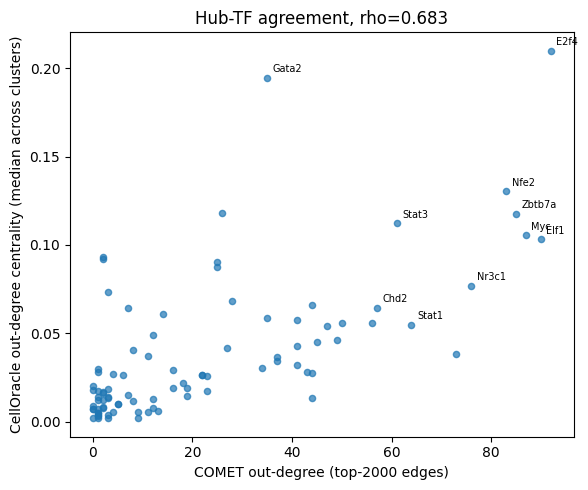

In [8]:
def topN_outdegree(mat, tf_names, n_edges=2000, eps=EPS):
    """Unweighted out-degree count from the top-n_edges strongest entries --
    matches CellOracle's g.degree(mode="out") on its filter_links(threshold_number=2000) graph."""
    flat = np.abs(mat).ravel()
    nz = np.flatnonzero(flat > eps)
    top_flat = nz[np.argsort(flat[nz])[::-1][:min(n_edges, len(nz))]]
    _, ti = np.unravel_index(top_flat, mat.shape)
    return pd.Series(np.bincount(ti, minlength=mat.shape[1]), index=tf_names)


comet_hub = topN_outdegree(comet_global, A_tfs, n_edges=2000)

ns = network_scores.copy()
ns["gene"] = ns.index
co_hub = ns[ns["gene"].isin(A_tfs)].groupby("gene")["degree_centrality_out"].median().reindex(A_tfs)

both = pd.DataFrame({"comet_hub": comet_hub, "co_hub": co_hub}).dropna()
rho, pval = spearmanr(both["comet_hub"], both["co_hub"])
print(f"Hub-TF agreement (Spearman), matched out-degree count, n={len(both)} TFs: rho={rho:.3f}, p={pval:.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(both["comet_hub"], both["co_hub"], s=20, alpha=0.7)
top10 = (both["comet_hub"].rank() + both["co_hub"].rank()).sort_values().index[-10:]
for g in top10:
    ax.annotate(g, (both.loc[g, "comet_hub"], both.loc[g, "co_hub"]), fontsize=7,
                xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("COMET out-degree (top-2000 edges)")
ax.set_ylabel("CellOracle out-degree centrality (median across clusters)")
ax.set_title(f"Hub-TF agreement, rho={rho:.3f}")
plt.tight_layout()
plt.show()

## Summary (raw_count_int fix applied, D=4)

- **Gene/TF universe overlap is nearly total**: 1848/1848 COMET genes and 89/90 COMET TFs are also in CellOracle's base-GRN universe.

- **Population-level edge overlap improved meaningfully** after the `raw_count_int` fix: top-10% per-TF Jaccard = 0.178 vs. a permutation null of 0.026 (6.97x over the random floor — up from 3.4x before the fix). Union-support Spearman (abs) = 0.202, up from 0.024 before the fix.

- **COMET's 4 dictionary atoms map onto distinct, coherent real cell types** (`2Ery`, `13Baso`, `14Mo`, `7MEP`).

- **Cell-level discrimination got worse, not just "still bad"**: accuracy 0.010 vs. shuffle null 0.023 ± 0.006 (nominal chance 1/16 = 0.062), p=0.985 — below its own permutation null, whereas before the fix it was merely at chance (0.067 vs 0.070). This is the standout negative result and the most important thing to chase next.

- **Hub-TF agreement**: matched out-degree count (top-2000 edges by weight, same as CellOracle's `filter_links(threshold_number=2000)` budget) — rho = 0.683 (p=1.6e-13, n=89).

**Overall picture:** the `raw_count_int` fix (removing the log1p-on-negative-values corruption) improved every population-level and hub-level metric, but cell-level discrimination got worse in absolute terms — consistent with Paul15's very low sequencing depth (mean ~1,351 total counts/cell vs. Velten's ~486,000) making single-cell GRN estimates noisy and depth-confounded under fully unnormalized counts, even though population averaging nets a benefit at the aggregate level. Next: try library-size-normalized + log1p (non-negative, depth-corrected, variance-stabilized) instead of fully raw counts, to see if it fixes the discrimination regression without losing the population-level gains.